# 📈 Linear Regression from Scratch

**Goal:** Predict a continuous output $\hat{y}$ from one or more input features $x$.

---

## 1. Algorithm Intuition

Linear Regression assumes the target $y$ is a **linear combination** of the features:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \ldots + w_n x_n + b = \mathbf{x}^T \mathbf{w} + b$$

**Where:**
- $\mathbf{x} \in \mathbb{R}^n$ — feature vector for one training example
- $\mathbf{w} \in \mathbb{R}^n$ — weight vector (one weight per feature)
- $b \in \mathbb{R}$ — bias (intercept) term
- $\hat{y}$ — predicted value

We learn $\mathbf{w}$ and $b$ by minimising the **Mean Squared Error (MSE) cost**:

$$J(\mathbf{w}, b) = \frac{1}{2m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

The factor $\frac{1}{2}$ is a mathematical convenience that cancels with the 2 that appears when taking the derivative.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $m$ | number of training examples |
| $n$ | number of features |
| $\alpha$ | learning rate |
| `num_iters` | number of gradient-descent iterations |
| `J_history` | list of cost values per iteration |

---

## 2. Gradient Descent Update Rules

We compute partial derivatives of $J$ with respect to each parameter and step in the downhill direction:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} X^T (\hat{y} - y)$$

$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$

$$\mathbf{w} := \mathbf{w} - \alpha \frac{\partial J}{\partial \mathbf{w}}, \quad b := b - \alpha \frac{\partial J}{\partial b}$$

> **Note:** Both $\mathbf{w}$ and $b$ must be updated **simultaneously** using the gradients computed *before* any update.


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Data Generation

We generate data from a known line $y = 3x + 5$ plus Gaussian noise, so we can verify our learned parameters are close to the true values.

In [2]:
# True parameters we want to recover
true_w = np.array([3.0])   # single feature weight
true_b = 5.0

m = 200          # number of training examples
noise_std = 2.0

# Feature matrix: shape (m, 1)
X_all = np.random.randn(m, 1)
# Target vector: shape (m,)
y_all = X_all @ true_w + true_b + np.random.randn(m) * noise_std

print(f"X shape: {X_all.shape}")
print(f"y shape: {y_all.shape}")

X shape: (200, 1)
y shape: (200,)


## 5. Train / Test Split

We split the data 80/20 and **fit the feature scaler on the training set only**, then apply it to both sets.

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=42):
    """Randomly split X and y into train / test sets."""
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(y))
    split = int(len(y) * (1 - test_ratio))
    train_idx, test_idx = indices[:split], indices[split:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 160, Test size: 40


In [4]:
def normalize(X_train, X_test):
    """Z-score normalise using train-set statistics only."""
    mu = X_train.mean(axis=0)       # shape (n,)
    sigma = X_train.std(axis=0)     # shape (n,)
    sigma[sigma == 0] = 1           # avoid division by zero
    X_train_norm = (X_train - mu) / sigma
    X_test_norm  = (X_test  - mu) / sigma
    return X_train_norm, X_test_norm, mu, sigma

X_train_n, X_test_n, mu, sigma = normalize(X_train, X_test)
print(f"Train mean ≈ {X_train_n.mean():.4f}, std ≈ {X_train_n.std():.4f}")

Train mean ≈ -0.0000, std ≈ 1.0000


## 6. Cost Function

In [5]:
def compute_cost(X, y, w, b):
    """
    Compute MSE cost  J = (1 / 2m) * sum((y_hat - y)^2).

    Parameters
    ----------
    X : ndarray, shape (m, n)
    y : ndarray, shape (m,)
    w : ndarray, shape (n,)
    b : float

    Returns
    -------
    J : float
    """
    m = X.shape[0]
    y_hat = X @ w + b          # predictions, shape (m,)
    errors = y_hat - y         # shape (m,)
    J = np.sum(errors ** 2) / (2 * m)
    return J

## 7. Gradient Computation

In [6]:
def compute_gradient(X, y, w, b):
    """
    Compute gradients dJ/dw and dJ/db.

    dJ/dw = (1/m) * X^T @ (y_hat - y)   shape (n,)
    dJ/db = (1/m) * sum(y_hat - y)       scalar
    """
    m = X.shape[0]
    y_hat = X @ w + b          # shape (m,)
    errors = y_hat - y         # shape (m,)

    dw = (X.T @ errors) / m   # shape (n,)
    db = np.sum(errors) / m   # scalar
    return dw, db

## 8. Gradient Descent Loop

In [7]:
def gradient_descent(X, y, alpha, num_iters):
    """
    Run gradient descent and return learned parameters + cost history.

    Parameters
    ----------
    X        : ndarray, shape (m, n)
    y        : ndarray, shape (m,)
    alpha    : float  — learning rate
    num_iters: int    — number of iterations

    Returns
    -------
    w         : ndarray, shape (n,)
    b         : float
    J_history : list of floats, length num_iters
    """
    n = X.shape[1]
    w = np.zeros(n)   # initialise weights to zero
    b = 0.0           # initialise bias to zero
    J_history = []

    for i in range(num_iters):
        dw, db = compute_gradient(X, y, w, b)

        # Simultaneous update
        w = w - alpha * dw
        b = b - alpha * db

        J_history.append(compute_cost(X, y, w, b))

        if i % 500 == 0:
            print(f"Iter {i:5d} | Cost: {J_history[-1]:.4f}")

    return w, b, J_history

## 9. Train the Model

In [8]:
alpha     = 0.1
num_iters = 2000

w, b, J_history = gradient_descent(X_train_n, y_train, alpha, num_iters)

print(f"\nLearned w = {w}, b = {b:.4f}")
print(f"True    w ≈ {true_w * sigma}, b ≈ {true_b + true_w @ mu:.4f}  (scaled-space equivalents)")

Iter     0 | Cost: 16.4235
Iter   500 | Cost: 2.0350
Iter  1000 | Cost: 2.0350
Iter  1500 | Cost: 2.0350

Learned w = [2.81009026], b = 5.2565
True    w ≈ [2.68895251], b ≈ 4.9795  (scaled-space equivalents)


## 10. Visualisations

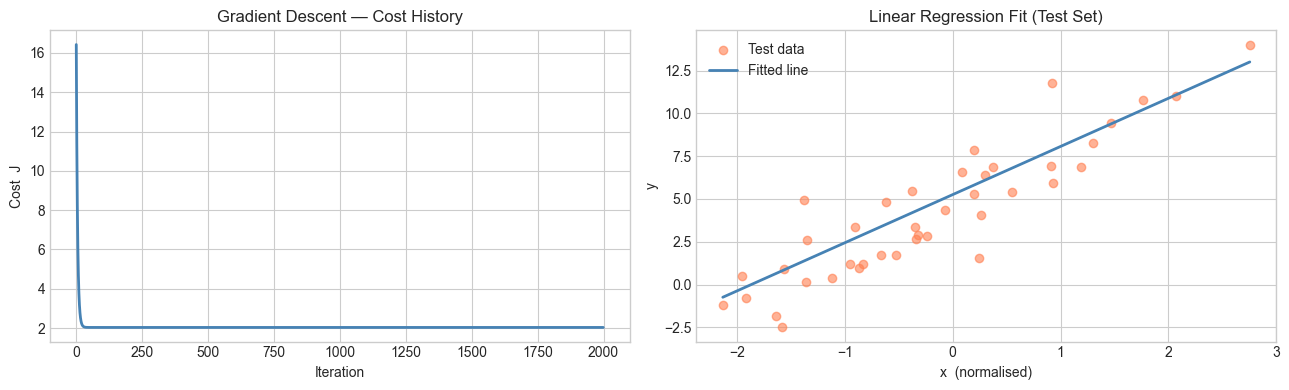

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- Cost history ---
axes[0].plot(J_history, color='steelblue', linewidth=2)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Cost  J')
axes[0].set_title('Gradient Descent — Cost History')

# --- Regression line on test set ---
x_line = np.linspace(X_test_n.min(), X_test_n.max(), 100).reshape(-1, 1)
y_line = x_line @ w + b

axes[1].scatter(X_test_n, y_test, alpha=0.6, color='coral', label='Test data')
axes[1].plot(x_line, y_line, color='steelblue', linewidth=2, label='Fitted line')
axes[1].set_xlabel('x  (normalised)')
axes[1].set_ylabel('y')
axes[1].set_title('Linear Regression Fit (Test Set)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 11. Evaluation Metrics

In [10]:
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = X_train_n @ w + b
y_pred_test  = X_test_n  @ w + b

mse_train = mean_squared_error(y_train, y_pred_train)
mse_test  = mean_squared_error(y_test,  y_pred_test)
r2_train  = r2_score(y_train, y_pred_train)
r2_test   = r2_score(y_test,  y_pred_test)

print(f"{'Metric':<20} {'Train':>10} {'Test':>10}")
print("-" * 42)
print(f"{'MSE':<20} {mse_train:>10.4f} {mse_test:>10.4f}")
print(f"{'RMSE':<20} {mse_train**0.5:>10.4f} {mse_test**0.5:>10.4f}")
print(f"{'R² score':<20} {r2_train:>10.4f} {r2_test:>10.4f}")

Metric                    Train       Test
------------------------------------------
MSE                      4.0700     3.0005
RMSE                     2.0174     1.7322
R² score                 0.6599     0.7958


## 12. Residual Plot

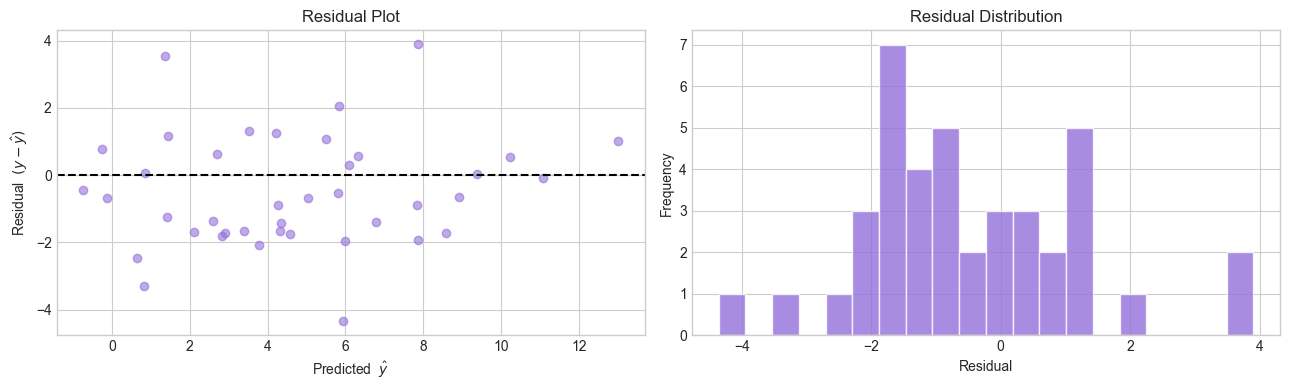

In [11]:
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(y_pred_test, residuals, alpha=0.6, color='mediumpurple')
axes[0].axhline(0, color='black', linewidth=1.5, linestyle='--')
axes[0].set_xlabel('Predicted  $\\hat{y}$')
axes[0].set_ylabel('Residual  $(y - \\hat{y})$')
axes[0].set_title('Residual Plot')

axes[1].hist(residuals, bins=20, color='mediumpurple', edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution')

plt.tight_layout()
plt.show()

## 13. Observations and Limitations

### What we observed
- The cost $J$ decreases smoothly — gradient descent is converging correctly.
- The learned $\mathbf{w}$ and $b$ are close to the scaled equivalents of the true parameters ($w=3, b=5$).
- The R² score on the test set is high, indicating the model generalises well to unseen data.
- Residuals are roughly normally distributed and centred around zero — a good sign.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Linearity assumption** | If the true relationship is non-linear, the model underfits (see Polynomial Regression). |
| **Sensitive to outliers** | MSE squares errors, so large outliers dominate the loss. |
| **Feature scaling required** | Gradient descent can be very slow without normalisation when features have different scales. |
| **No regularisation** | Adding many features can lead to overfitting (see Ridge Regression). |
| **Learning rate sensitivity** | A too-large $\alpha$ causes divergence; too-small $\alpha$ is slow. |
